# 13 Aspect-Based Sentiment

Tiap teks punya beberapa aspek, dan tiap aspek punya polaritas sendiri. Contoh: ulasan hotel HoASA,
tapi polanya sama untuk komentar MBG, misalnya aspek rasa, kebersihan, dan distribusi.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Sentimen per aspek |
| **Unit prediksi** | Satu ulasan mendapat satu kelas untuk tiap aspek |
| **Metrik** | Macro-F1 per aspek, lalu dirata-rata |
| **Masalah terbesar** | Mayoritas label netral karena aspek tidak disebut (59% sampai 92%), dan kelas positif pada banyak aspek di bawah 3%. |
| **Data contoh** | HoASA: 2.283 latih, 285 valid, 286 test, 10 aspek |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** target berupa polaritas per aspek, misalnya kolom `rasa`, `kebersihan`, `harga` dengan isi
positif atau negatif. Metriknya biasanya macro-F1 per aspek lalu dirata-rata.

**Yang perlu diganti kalau datanya beda:**
- `DATA_FOLDER`, `TEXT_COL`, `ASPECTS`, `POLARITIES`.
- Kalau tiap aspek hanya ada atau tidak ada, pakai folder `12`.
- Kalau frasa aspeknya harus diambil dari teks, pakai folder `17`.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya TF-IDF per aspek, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
DATA_FOLDER = "hoasa_absa-airy"
TEXT_COL = "review"
ASPECTS = [
    "ac",
    "air_panas",
    "bau",
    "general",
    "kebersihan",
    "linen",
    "service",
    "sunrise_meal",
    "tv",
    "wifi",
]
POLARITIES = ["neg", "neut", "pos"]

SETTINGS = {
    "cepat": {"epochs": 4, "model_runs": [("indobert", SEED)]},
    "penuh": {
        "epochs": 8,
        "model_runs": [("indobert", SEED), ("indobert", SEED + 1), ("indobertweet", SEED)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'epochs': 8, 'model_runs': [('indobert', 42), ('indobert', 43), ('indobertweet', 42)]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [6]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat train, valid, dan test. Label langka `neg_pos` berarti satu aspek bercampur, dan digabung ke `neg`
karena keluhan biasanya lebih penting.

In [7]:
from sklearn.metrics import f1_score  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import AutoModel, AutoTokenizer  # noqa: E402
from transformers import get_linear_schedule_with_warmup  # noqa: E402


def read_split(split: str) -> pd.DataFrame:
    path = EXTRA_DATA_DIR / "indonlu/dataset" / DATA_FOLDER / f"{split}_preprocess.csv"
    return pd.read_csv(path).replace({"neg_pos": "neg"}).head(N_ROWS)


train, valid, test = read_split("train"), read_split("valid"), read_split("test")
print(f"latih={len(train)} | valid={len(valid)} | test={len(test)}")
text_profile(train[TEXT_COL])

latih=2283 | valid=285 | test=286


baris                2283.0
kosong                  0.0
duplikat_persis_%       0.0
kata_median            14.0
kata_p95               51.0
kata_maks             140.0
ada_url_%               0.0
ada_emoji_%             1.7
dtype: float64

Sebaran polaritas per aspek. Aspek yang hampir selalu `neut` adalah sumber masalah utama.

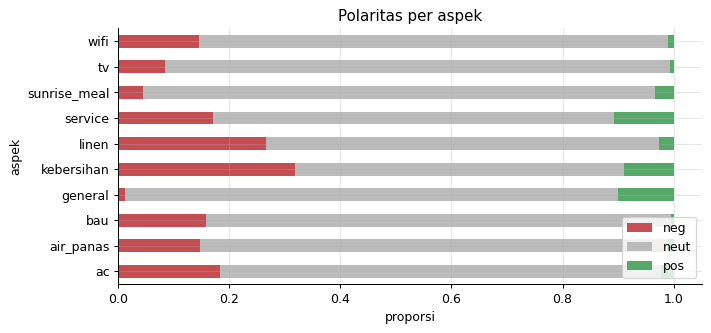

,neg,neut,pos
ac,0.183,0.795,0.022
air_panas,0.147,0.842,0.011
bau,0.158,0.837,0.005
general,0.013,0.886,0.101
kebersihan,0.319,0.591,0.090
linen,0.266,0.707,0.028
service,0.170,0.722,0.108
sunrise_meal,0.044,0.923,0.033
tv,0.085,0.909,0.006
wifi,0.145,0.845,0.011


In [8]:
distribution = (
    pd.DataFrame({a: train[a].value_counts(normalize=True) for a in ASPECTS})
    .T.reindex(columns=POLARITIES)
    .fillna(0)
    .round(3)
)
fig, ax = plt.subplots(figsize=(8, 3.8))
distribution.plot.barh(stacked=True, ax=ax, color=["#C44E52", "#BBBBBB", "#55A868"])
ax.set(title="Polaritas per aspek", xlabel="proporsi", ylabel="aspek")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
distribution

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Netral sangat dominan | Tebak netral sudah menjadi baseline, macro-F1 0,2956 |
| Aspek `general` paling samar | Laporkan F1 per aspek, jangan hanya rata-rata |
| Data latih kecil | Satu model berbagi encoder untuk semua aspek |

## 5. Preprocessing

Pembersihan ringan, dan label diubah menjadi matriks angka berukuran baris kali aspek.

In [9]:
polarity_to_id = {name: i for i, name in enumerate(POLARITIES)}
for frame in (train, valid, test):
    frame["clean"] = frame[TEXT_COL].map(clean_text)
y_train = train[ASPECTS].replace(polarity_to_id).to_numpy(dtype=int)
y_valid = valid[ASPECTS].replace(polarity_to_id).to_numpy(dtype=int)
y_test = test[ASPECTS].replace(polarity_to_id).to_numpy(dtype=int)
print("ukuran label:", y_train.shape)

ukuran label: (2283, 10)


## 6. Validasi

Memakai split valid dan test yang disediakan. Valid untuk memilih, test hanya untuk laporan. Metrik utama
macro-F1 yang dihitung per aspek lalu dirata-rata, sama seperti evaluasi resmi IndoNLU.

In [10]:
def aspect_macro_f1(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    scores = [
        f1_score(y_true[:, a], y_pred[:, a], average="macro", zero_division=0)
        for a in range(y_true.shape[1])
    ]
    return float(np.mean(scores))


_check = np.array([[0], [1]])
assert aspect_macro_f1(_check, _check) == 1.0
results: list[dict] = []


def record(name: str, pred_valid, pred_test) -> None:
    results.append(
        {
            "model": name,
            "valid": round(aspect_macro_f1(y_valid, pred_valid), 4),
            "test": round(aspect_macro_f1(y_test, pred_test), 4),
        }
    )
    print(results[-1])

## 7. Baseline

Tebak `neut` di semua aspek, lalu TF-IDF + regresi logistik untuk tiap aspek.

In [11]:
neutral = polarity_to_id["neut"]
record("semua_netral", np.full_like(y_valid, neutral), np.full_like(y_test, neutral))

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
x_train = vectorizer.fit_transform(train["clean"])
x_valid, x_test = vectorizer.transform(valid["clean"]), vectorizer.transform(test["clean"])
tfidf_valid, tfidf_test = np.zeros_like(y_valid), np.zeros_like(y_test)
for a in range(len(ASPECTS)):
    model = LogisticRegression(C=3.0, max_iter=2000, class_weight="balanced").fit(
        x_train, y_train[:, a]
    )
    tfidf_valid[:, a], tfidf_test[:, a] = model.predict(x_valid), model.predict(x_test)
record("tfidf_per_aspek", tfidf_valid, tfidf_test)

{'model': 'semua_netral', 'valid': 0.2943, 'test': 0.2956}


{'model': 'tfidf_per_aspek', 'valid': 0.7166, 'test': 0.7117}


## 8. Model Utama

**Satu encoder dengan banyak kepala.** Encoder dipakai bersama, dan tiap aspek punya lapisan keluaran
sendiri. Lebih cepat daripada melatih satu model per aspek, dan aspek langka terbantu oleh aspek lain.
Bobot kelas dipasang per aspek supaya model tidak hanya menebak `neut`.

In [12]:
class MultiHeadClassifier(torch.nn.Module):
    def __init__(self, model_name: str, n_aspects: int, n_classes: int):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_DIR / model_name)
        self.head = torch.nn.Linear(self.encoder.config.hidden_size, n_aspects * n_classes)
        self.shape = (n_aspects, n_classes)
        self.dropout = torch.nn.Dropout(0.1)

    def forward(self, input_ids, attention_mask):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.head(self.dropout(hidden[:, 0])).view(-1, *self.shape)


@torch.inference_mode()
def predict_probs(model, ids, mask, batch_size=64) -> np.ndarray:
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(
                ids[start : start + batch_size].to(DEVICE),
                mask[start : start + batch_size].to(DEVICE),
            )
        chunks.append(torch.softmax(logits.float(), dim=-1).cpu())
    return torch.cat(chunks).numpy()


def train_multihead(model_name: str, epochs: int, seed: int, max_len=128, batch_size=32):
    seed_everything(seed)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / model_name)

    def encode(frame):
        tokens = tokenizer(
            frame["clean"].tolist(),
            padding="max_length",
            truncation=True,
            max_length=max_len,
            return_tensors="pt",
        )
        return tokens["input_ids"], tokens["attention_mask"]

    ids, mask = encode(train)
    target = torch.tensor(y_train)
    model = MultiHeadClassifier(model_name, len(ASPECTS), len(POLARITIES)).to(DEVICE)
    weights = np.stack(
        [
            len(y_train)
            / (len(POLARITIES) * np.maximum(np.bincount(y_train[:, a], minlength=3), 1))
            for a in range(len(ASPECTS))
        ]
    )
    weights = torch.tensor(np.clip(weights, 0.2, 10), dtype=torch.float).to(DEVICE)
    loader = DataLoader(TensorDataset(ids, mask, target), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)
    steps = epochs * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            batch_y = batch_y.to(DEVICE)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(batch_ids.to(DEVICE), batch_mask.to(DEVICE))
                loss = sum(
                    torch.nn.functional.cross_entropy(
                        logits[:, a], batch_y[:, a], weight=weights[a]
                    )
                    for a in range(len(ASPECTS))
                ) / len(ASPECTS)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
    outputs = [predict_probs(model, *encode(f)) for f in (valid, test)]
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs


probs_valid = np.zeros((*y_valid.shape, len(POLARITIES)))
probs_test = np.zeros((*y_test.shape, len(POLARITIES)))
with stage("transformer"):
    if USE_PRETRAINED:
        for model_name, seed in SETTINGS["model_runs"]:
            run_valid, run_test = train_multihead(model_name, SETTINGS["epochs"], seed)
            probs_valid += run_valid / len(SETTINGS["model_runs"])
            probs_test += run_test / len(SETTINGS["model_runs"])
    else:
        probs_valid = np.eye(len(POLARITIES))[tfidf_valid]
        probs_test = np.eye(len(POLARITIES))[tfidf_test]
record("model_utama", probs_valid.argmax(-1), probs_test.argmax(-1))

[waktu] transformer: 374 detik
{'model': 'model_utama', 'valid': 0.8191, 'test': 0.8494}


## 9. Post-processing

Pengali polaritas per aspek, difit di valid. Karena valid kecil, grid dibuat kasar supaya tidak overfit,
dan hasilnya hanya dipakai kalau valid naik cukup jelas.

In [13]:
def fit_aspect_multipliers(probs: np.ndarray, target: np.ndarray) -> np.ndarray:
    """Cari pengali per aspek dan polaritas dengan pencarian bergantian."""
    multipliers = np.ones(probs.shape[1:])
    grid = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
    for a in range(probs.shape[1]):
        for cls in range(probs.shape[2]):
            scores = []
            for value in grid:
                trial = multipliers[a].copy()
                trial[cls] = value
                pred = (probs[:, a] * trial).argmax(1)
                scores.append(f1_score(target[:, a], pred, average="macro", zero_division=0))
            multipliers[a, cls] = grid[int(np.argmax(scores))]
    return multipliers


half = len(y_valid) // 2
half_multipliers = fit_aspect_multipliers(probs_valid[:half], y_valid[:half])
honest_gain = aspect_macro_f1(
    y_valid[half:], (probs_valid[half:] * half_multipliers[None]).argmax(-1)
) - aspect_macro_f1(y_valid[half:], probs_valid[half:].argmax(-1))
multipliers = fit_aspect_multipliers(probs_valid, y_valid)
use_multipliers = honest_gain > 0.005
final_valid = (
    (probs_valid * multipliers[None]).argmax(-1) if use_multipliers else probs_valid.argmax(-1)
)
final_test = (
    (probs_test * multipliers[None]).argmax(-1) if use_multipliers else probs_test.argmax(-1)
)
record(
    "model_utama_plus_pengali" if use_multipliers else "model_utama_final", final_valid, final_test
)
print(f"kenaikan jujur di separuh valid: {honest_gain:+.4f} -> pakai pengali: {use_multipliers}")

{'model': 'model_utama_plus_pengali', 'valid': 0.8778, 'test': 0.8412}
kenaikan jujur di separuh valid: +0.0060 -> pakai pengali: True


## 10. Post-analysis

**Tabel perbandingan.**

In [14]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,valid,test
0,semua_netral,0.2943,0.2956
1,tfidf_per_aspek,0.7166,0.7117
2,model_utama,0.8191,0.8494
3,model_utama_plus_pengali,0.8778,0.8412


**Skor per aspek.** Aspek dengan sedikit data non-netral biasanya paling lemah.

In [15]:
pd.DataFrame(
    {
        "non_netral_latih": (y_train != neutral).sum(0),
        "f1_test": [
            round(f1_score(y_test[:, a], final_test[:, a], average="macro", zero_division=0), 3)
            for a in range(len(ASPECTS))
        ],
    },
    index=ASPECTS,
).sort_values("f1_test")

,non_netral_latih,f1_test
general,260,0.616
air_panas,361,0.710
wifi,355,0.788
bau,372,0.825
linen,670,0.831
sunrise_meal,175,0.899
kebersihan,933,0.917
tv,208,0.931
service,634,0.943
ac,469,0.951


**Confusion matrix gabungan** semua aspek pada test.

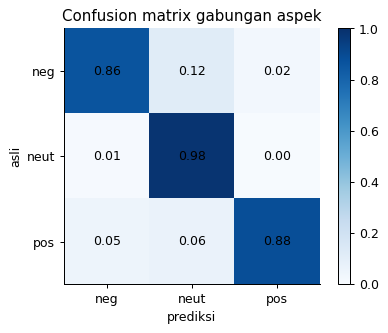

In [16]:
plot_confusion(y_test.ravel(), final_test.ravel(), POLARITIES, "Confusion matrix gabungan aspek")

## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [17]:
pd.DataFrame(np.array(POLARITIES)[final_test], columns=ASPECTS).rename_axis("id").to_csv(
    RESULT_DIR / "submission.csv"
)
run_summary(
    "absa",
    len(train),
    {r["model"]: {"valid": r["valid"], "test": r["test"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=absa mode=penuh n_rows=2283 total_detik=400 gpu=True
{
 "semua_netral": {
  "valid": 0.2943,
  "test": 0.2956
 },
 "tfidf_per_aspek": {
  "valid": 0.7166,
  "test": 0.7117
 },
 "model_utama": {
  "valid": 0.8191,
  "test": 0.8494
 },
 "model_utama_plus_pengali": {
  "valid": 0.8778,
  "test": 0.8412
 }
}


**Poin untuk presentasi**

- Model utama test 0,8494, jauh di atas TF-IDF per aspek 0,7117.
- Pengali lolos syarat di separuh valid, tapi test turun sedikit ke 0,8412. Selisih ini kecil, dan valid 0,8778 terlalu optimistis karena pengali juga difit di valid.
- Aspek terlemah `general` (0,616), terkuat `ac` (0,951).
- Data ulasan hotel. Untuk MBG, aspek bisa diganti menjadi rasa, kebersihan, gizi, distribusi, dan anggaran.